In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "data/processed/electricity_weather_integrated_2025.csv"
)

df["hour_ending_utc"] = pd.to_datetime(
    df["hour_ending_utc"], utc=True
)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (8760, 11)
            hour_ending_utc        date  month day_of_week  hour  \
0 2025-01-01 07:00:00+00:00  2025-01-01      1   Wednesday     1   
1 2025-01-01 08:00:00+00:00  2025-01-01      1   Wednesday     2   
2 2025-01-01 09:00:00+00:00  2025-01-01      1   Wednesday     3   
3 2025-01-01 10:00:00+00:00  2025-01-01      1   Wednesday     4   
4 2025-01-01 11:00:00+00:00  2025-01-01      1   Wednesday     5   

      demand_mw           weather_hour_utc                   hour_utc  \
0  43223.859905  2025-01-01 06:00:00+00:00  2025-01-01 06:00:00+00:00   
1  43122.532212  2025-01-01 07:00:00+00:00  2025-01-01 07:00:00+00:00   
2  42918.511847  2025-01-01 08:00:00+00:00  2025-01-01 08:00:00+00:00   
3  42780.783583  2025-01-01 09:00:00+00:00  2025-01-01 09:00:00+00:00   
4  43253.234707  2025-01-01 10:00:00+00:00  2025-01-01 10:00:00+00:00   

   avg_temperature_c  avg_humidity_pct  avg_feels_like_c  
0             7.7750            62.625            4.2125  
1       

In [3]:
print("Total records:", len(df))

print("Missing weather values:")
print(df[
    ["avg_temperature_c",
     "avg_humidity_pct",
     "avg_feels_like_c"]
].isnull().sum())

print("\nDuplicate electricity hours:")
print(df["hour_ending_utc"].duplicated().sum())

Total records: 8760
Missing weather values:
avg_temperature_c    0
avg_humidity_pct     0
avg_feels_like_c     0
dtype: int64

Duplicate electricity hours:
0


In [4]:
df["hour_ending_utc"] = pd.to_datetime(
    df["hour_ending_utc"], utc=True
)

df["weather_hour_utc"] = pd.to_datetime(
    df["weather_hour_utc"], utc=True
)

time_difference = (
    df["hour_ending_utc"] - df["weather_hour_utc"]
)

print(time_difference.value_counts())

0 days 01:00:00    8760
Name: count, dtype: int64


In [5]:
print(df[
    ["hour_ending_utc", "weather_hour_utc", "demand_mw"]
].head(3))

print("\nLast 3 records:")
print(df[
    ["hour_ending_utc", "weather_hour_utc", "demand_mw"]
].tail(3))

            hour_ending_utc          weather_hour_utc     demand_mw
0 2025-01-01 07:00:00+00:00 2025-01-01 06:00:00+00:00  43223.859905
1 2025-01-01 08:00:00+00:00 2025-01-01 07:00:00+00:00  43122.532212
2 2025-01-01 09:00:00+00:00 2025-01-01 08:00:00+00:00  42918.511847

Last 3 records:
               hour_ending_utc          weather_hour_utc     demand_mw
8757 2026-01-01 04:00:00+00:00 2026-01-01 03:00:00+00:00  48256.977350
8758 2026-01-01 05:00:00+00:00 2026-01-01 04:00:00+00:00  47394.684164
8759 2026-01-01 06:00:00+00:00 2026-01-01 05:00:00+00:00  46810.796215


In [6]:
print("Electricity start:", df["hour_ending_utc"].min())
print("Electricity end:", df["hour_ending_utc"].max())

print("Weather start:", df["weather_hour_utc"].min())
print("Weather end:", df["weather_hour_utc"].max())

Electricity start: 2025-01-01 07:00:00+00:00
Electricity end: 2026-01-01 06:00:00+00:00
Weather start: 2025-01-01 06:00:00+00:00
Weather end: 2026-01-01 05:00:00+00:00


In [7]:
df["hour_utc"] = pd.to_datetime(
    df["hour_utc"], utc=True
)

df["weather_hour_utc"] = pd.to_datetime(
    df["weather_hour_utc"], utc=True
)

print("Weather timestamp mismatches:")
print((df["hour_utc"] != df["weather_hour_utc"]).sum())

Weather timestamp mismatches:
0


In [8]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (8760, 11)

Columns:
['hour_ending_utc', 'date', 'month', 'day_of_week', 'hour', 'demand_mw', 'weather_hour_utc', 'hour_utc', 'avg_temperature_c', 'avg_humidity_pct', 'avg_feels_like_c']

Data types:
hour_ending_utc      datetime64[us, UTC]
date                                 str
month                              int64
day_of_week                          str
hour                               int64
demand_mw                        float64
weather_hour_utc     datetime64[us, UTC]
hour_utc             datetime64[us, UTC]
avg_temperature_c                float64
avg_humidity_pct                 float64
avg_feels_like_c                 float64
dtype: object


In [9]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nCSV files:")
for file in Path("..").rglob("*.csv"):
    print(file)

Current working directory:
/Users/akshaybanala/Documents/texas_electricity_project/notebooks

CSV files:
../notebooks/data/processed/weather_2025_extended.csv
../notebooks/data/processed/electricity_weather_integrated_2025.csv
../data/processed/ercot_zones_2025.csv
../data/processed/texas_weather_era5_2025.csv
../data/processed/dallas_weather_clean_2025.csv
../data/processed/texas_weather_8cities_2025.csv
../data/processed/texas_weather_7cities_2025.csv
../data/processed/ercot_statewide_2025.csv
../data/raw/dallas_weather_2025.csv
../.venv/lib/python3.14/site-packages/matplotlib/mpl-data/sample_data/msft.csv
../.venv/lib/python3.14/site-packages/matplotlib/mpl-data/sample_data/data_x_x2_x3.csv
../.venv/lib/python3.14/site-packages/matplotlib/mpl-data/sample_data/Stocks.csv
../.venv/lib/python3.14/site-packages/tornado/test/csv_translations/fr_FR.csv
../.venv/lib/python3.14/site-packages/numpy/random/tests/data/philox-testset-1.csv
../.venv/lib/python3.14/site-packages/numpy/random/test

In [10]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "electricity_weather_integrated_2025.csv"

df.to_csv(output_file, index=False)

print("Integrated dataset saved successfully!")
print("Location:", output_file.resolve())
print("Records:", len(df))

Integrated dataset saved successfully!
Location: /Users/akshaybanala/Documents/texas_electricity_project/data/processed/electricity_weather_integrated_2025.csv
Records: 8760


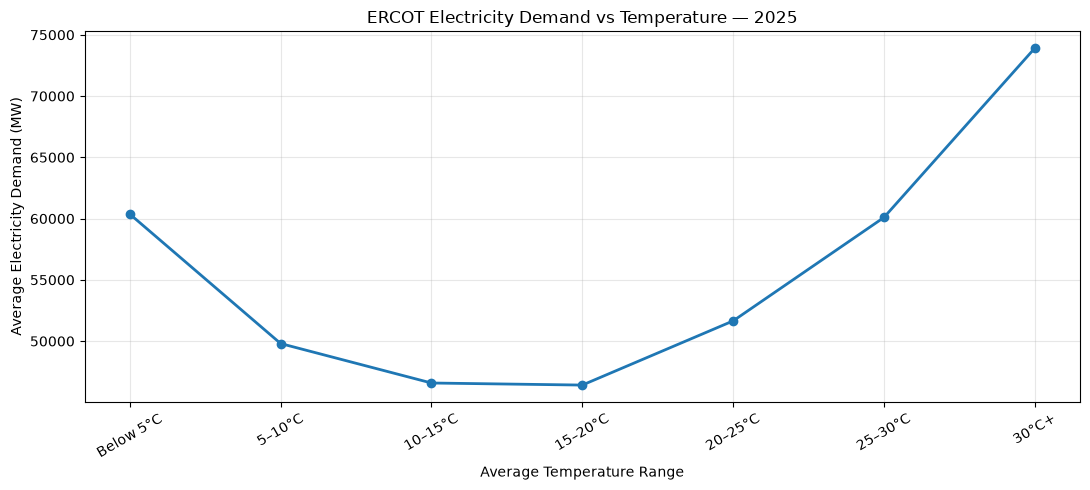

  temp_group          mean  count
0  Below 5°C  60363.195501    578
1     5–10°C  49799.710352    670
2    10–15°C  46580.211429    953
3    15–20°C  46411.927268   1405
4    20–25°C  51649.538380   1925
5    25–30°C  60093.453836   2005
6      30°C+  73909.648677   1224


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "data/processed/electricity_weather_integrated_2025.csv"
)

df["temp_group"] = pd.cut(
    df["avg_temperature_c"],
    bins=[-100, 5, 10, 15, 20, 25, 30, 100],
    labels=[
        "Below 5°C", "5–10°C", "10–15°C",
        "15–20°C", "20–25°C", "25–30°C", "30°C+"
    ],
    right=False
)

summary = (
    df.groupby("temp_group", observed=True)["demand_mw"]
    .agg(["mean", "count"])
    .reset_index()
)

plt.figure(figsize=(11, 5))
plt.plot(
    summary["temp_group"].astype(str),
    summary["mean"],
    marker="o",
    linewidth=2
)

plt.title("ERCOT Electricity Demand vs Temperature — 2025")
plt.xlabel("Average Temperature Range")
plt.ylabel("Average Electricity Demand (MW)")
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(summary)

In [13]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = df.dropna(
    subset=["avg_temperature_c", "demand_mw"]
).copy()

X = df[["avg_temperature_c"]].values
y = df["demand_mw"].values

# Linear relationship
linear_model = LinearRegression()
linear_model.fit(X, y)

linear_r2 = r2_score(
    y, linear_model.predict(X)
)

# Quadratic relationship
X_quad = np.column_stack([
    X[:, 0],
    X[:, 0] ** 2
])

quad_model = LinearRegression()
quad_model.fit(X_quad, y)

quadratic_r2 = r2_score(
    y, quad_model.predict(X_quad)
)

print("Linear R²:", round(linear_r2, 4))
print("Quadratic R²:", round(quadratic_r2, 4))

Linear R²: 0.2896
Quadratic R²: 0.8683


In [14]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = df.dropna(
    subset=["avg_temperature_c", "demand_mw"]
).copy()

X = df[["avg_temperature_c"]].values
y = df["demand_mw"].values

# Linear relationship
linear_model = LinearRegression()
linear_model.fit(X, y)

linear_r2 = r2_score(
    y, linear_model.predict(X)
)

# Quadratic relationship
X_quad = np.column_stack([
    X[:, 0],
    X[:, 0] ** 2
])

quad_model = LinearRegression()
quad_model.fit(X_quad, y)

quadratic_r2 = r2_score(
    y, quad_model.predict(X_quad)
)

print("Linear R²:", round(linear_r2, 4))
print("Quadratic R²:", round(quadratic_r2, 4))

Linear R²: 0.2896
Quadratic R²: 0.8683


In [15]:
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

# Sort chronologically
df = df.sort_values("hour_ending_utc").copy()

split = int(len(df) * 0.8)

train = df.iloc[:split]
test = df.iloc[split:]

def features(data, quadratic=False):
    temp = data["avg_temperature_c"].to_numpy()

    if quadratic:
        return np.column_stack([temp, temp ** 2])

    return temp.reshape(-1, 1)

for name, quadratic in [
    ("Linear", False),
    ("Quadratic", True)
]:
    model = LinearRegression()

    model.fit(
        features(train, quadratic),
        train["demand_mw"]
    )

    predictions = model.predict(
        features(test, quadratic)
    )

    print(f"\n{name} Model")
    print(
        "Test R²:",
        round(r2_score(test["demand_mw"], predictions), 4)
    )
    print(
        "Test MAE:",
        round(mean_absolute_error(
            test["demand_mw"], predictions
        ), 2),
        "MW"
    )


Linear Model
Test R²: -0.461
Test MAE: 5490.63 MW

Quadratic Model
Test R²: 0.4684
Test MAE: 3242.9 MW


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error

df = df.sort_values("hour_ending_utc").copy()

df["day_of_week"] = pd.to_datetime(
    df["date"]
).dt.dayofweek

split = int(len(df) * 0.8)

train = df.iloc[:split]
test = df.iloc[split:]

features = [
    "avg_temperature_c",
    "hour",
    "day_of_week",
    "month"
]

preprocessor = ColumnTransformer([
    (
        "temperature",
        PolynomialFeatures(
            degree=2,
            include_bias=False
        ),
        ["avg_temperature_c"]
    ),
    (
        "calendar",
        OneHotEncoder(handle_unknown="ignore"),
        ["hour", "day_of_week", "month"]
    )
])

model = Pipeline([
    ("features", preprocessor),
    ("regression", Ridge(alpha=10))
])

model.fit(train[features], train["demand_mw"])

predictions = model.predict(test[features])

print("Enhanced Model Test R²:",
      round(r2_score(test["demand_mw"], predictions), 4))

print("Enhanced Model Test MAE:",
      round(mean_absolute_error(
          test["demand_mw"], predictions
      ), 2), "MW")

Enhanced Model Test R²: 0.7688
Enhanced Model Test MAE: 2015.97 MW


/var/folders/0l/lcnr_63113790nrbyqz3sjxh0000gn/T/ipykernel_93198/2374759233.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  ).dt.dayofweek
